# Lab 4 — Assignment


**Based on:** Lab-4-b (Bernoulli, Binomial, Poisson, Normal, Uniform)


---

### Instructions

1. Run the **Setup** cell first. Do not modify it.
2. There are **10 questions** — two on each distribution. Attempt **all** of them.
3. Every question has three parts:
   - **(a)** and **(b)** — work these out **by hand** and type your working in the *Written answer* cell.
   - **(c)** — write **Python code** in the blank code cell provided and produce the plot asked for.
4. Use `DISCRETE_COLOR` for discrete plots (bars) and `CONTINUOUS_COLOR` for continuous plots (curves).
5. Every plot must have an **x-label, y-label and a title**. Marks are deducted for unlabelled plots.
6. Round all probabilities to **4 decimal places**.
7. Save the notebook with all outputs visible before submitting.

### Marks distribution

| Section | Questions | Marks each | Total |
|---|---|---|---|
| A — Bernoulli | Q1, Q2 | 5 | 10 |
| B — Binomial | Q3, Q4 | 5 | 10 |
| C — Poisson | Q5, Q6 | 5 | 10 |
| D — Normal | Q7, Q8 | 5 | 10 |
| E — Uniform | Q9, Q10 | 5 | 10 |
| | | **Total** | **50** |

### Quick reference — which function do I need?

| Task | `scipy.stats` call |
|---|---|
| $P(X = k)$, discrete | `.pmf(k, ...)` |
| $f(x)$, continuous | `.pdf(x, ...)` |
| $P(X \le x)$ | `.cdf(x, ...)` |
| $P(X > x)$ | `.sf(x, ...)` |
| Value with given $P(X \le x)$ | `.ppf(prob, ...)` |
| Mean / variance | `.mean(...)`, `.var(...)` |
| Random samples | `.rvs(..., size=n, random_state=seed)` |

---

## Setup
Run this cell first — do not change it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, factorial, exp, sqrt

DISCRETE_COLOR = "#0E9F9A"     # teal   -> discrete distributions
CONTINUOUS_COLOR = "#E4572E"   # orange -> continuous distributions
HIGHLIGHT_COLOR = "#F4A261"    # use this to highlight a bar or a shaded area

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Setup complete — you are ready to start.")

Setup complete — you are ready to start.


---
# Part A — Bernoulli distribution
*Recall:* $P(X=x) = p^x(1-p)^{1-x}$ for $x \in \{0,1\}$, $\;E[X]=p$, $\;Var(X)=p(1-p)$.

## Q1. The library gate scanner 

> 📚 The RFID gate at the college library reads a student's ID card correctly on the **first tap 92%** of the time. One student taps her card once.
>
> Let $X = 1$ if the card is read on the first tap, and $X = 0$ if it is not.
>
> **(a)** State the value of $p$ and find $P(X=1)$ and $P(X=0)$.
> **(b)** Find the mean and the variance of $X$, showing the substitution into the formulas.
> **(c)** Write Python code that:
> - builds the PMF of $X$ using `stats.bernoulli.pmf`,
> - draws a **bar chart** of the distribution in `DISCRETE_COLOR` with the ticks labelled `"Not read (0)"` and `"Read (1)"`,
> - writes the probability value on top of each bar,
> - prints the mean and the variance obtained from `scipy`, and checks that they match your hand answers in (b).

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [2]:
### (a) State the value of p and find P(X=1) and P(X=0)

Given that the RFID gate reads the card correctly on the first tap 92% of the time,

p = 0.92

For a Bernoulli distribution,

P(X=1) = p = 0.92

P(X=0) = 1 - p
= 1 - 0.92
= 0.08

Therefore,

P(X=1) = 0.92
P(X=0) = 0.08

For a Bernoulli distribution,

Mean = p

Mean = 0.92

Therefore,

Mean = 0.92

Variance = p(1-p)

Substituting p = 0.92,

Variance = 0.92(1 - 0.92)
= 0.92 × 0.08
= 0.0736

Therefore,

Variance = 0.0736


SyntaxError: invalid character '×' (U+00D7) (1075990957.py, line 35)

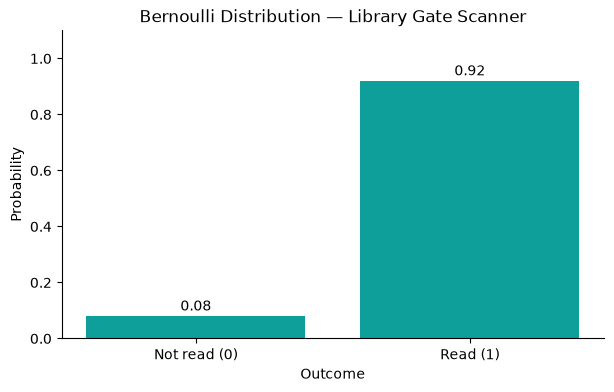

Mean from scipy: 0.92
Variance from scipy: 0.0736
Mean matches hand calculation: True
Variance matches hand calculation: True


In [3]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
# Part A — Bernoulli Distribution
# Q1(c) — Library Gate Scanner

p = 0.92
x = np.array([0, 1])

pmf = stats.bernoulli.pmf(x, p)

# Bar chart
plt.bar(x, pmf, color=DISCRETE_COLOR)

# X-axis labels
plt.xticks(x, ["Not read (0)", "Read (1)"])

plt.xlabel("Outcome")
plt.ylabel("Probability")
plt.title("Bernoulli Distribution — Library Gate Scanner")

# Display probability values on top of each bar
for i, value in enumerate(pmf):
    plt.text(x[i], value + 0.02, f"{value:.2f}", ha="center")

plt.ylim(0, 1.1)
plt.show()

# Mean and variance using scipy
mean_scipy = stats.bernoulli.mean(p)
variance_scipy = stats.bernoulli.var(p)

print("Mean from scipy:", mean_scipy)
print("Variance from scipy:", variance_scipy)

# Hand calculation values
mean_hand = 0.92
variance_hand = 0.0736

# Check whether scipy values match hand calculations
print("Mean matches hand calculation:", np.isclose(mean_scipy, mean_hand))
print("Variance matches hand calculation:", np.isclose(variance_scipy, variance_hand))


# ------------------------------------------------------------

## Q2. Estimating $p$ from attendance data &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 👆 A biometric attendance device records whether a student's fingerprint is accepted on the **first attempt**. Over one semester the device logged **2,000 scans**, of which **1,740** were accepted on the first attempt. Treat one scan as a single Bernoulli trial with $X=1$ for *accepted*.
>
> **(a)** Estimate $p$ from the data and write down the full PMF $P(X=x)$ with the estimated value substituted in.
> **(b)** Find the mean and variance. Then answer: for what value of $p$ would the variance of a Bernoulli variable be the **largest possible**, and what is that largest value? Justify your answer using the formula $Var(X)=p(1-p)$.
> **(c)** Write Python code that:
> - simulates 2,000 Bernoulli trials with your estimated $p$ using `stats.bernoulli.rvs(..., random_state=42)`,
> - prints the **simulated proportion** of successes next to the theoretical $p$,
> - plots the **theoretical PMF and the simulated relative frequencies side by side** as grouped bars with a legend,
> - plots $Var(X)=p(1-p)$ against $p$ for $p$ from 0 to 1 in a **second figure**, and marks the maximum point with a marker and an annotation.

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:

# ------------------------------------------------------------
### (a) Estimate p and write the full PMF

Given:

Total number of scans = 2000

Number of scans accepted on the first attempt = 1740

The estimated probability of success is:

p = Number of successes / Total number of trials

p = 1740 / 2000

p = 0.87

Therefore,

p = 0.87

and

1 - p = 1 - 0.87 = 0.13

For a Bernoulli random variable, the PMF is:

P(X = x) = p^x(1-p)^(1-x),  x = 0, 1

Substituting p = 0.87:

P(X = x) = (0.87)^x(0.13)^(1-x),  x = 0, 1

Therefore,

P(X = 0) = (0.87)^0(0.13)^1 = 0.13

P(X = 1) = (0.87)^1(0.13)^0 = 0.87

### (b) Find the mean and variance

For a Bernoulli distribution:

Mean = p

Mean = 0.87

Therefore,

Mean = 0.87

Variance = p(1-p)

Variance = 0.87(1 - 0.87)

Variance = 0.87 × 0.13

Variance = 0.1131

Therefore,

Variance = 0.1131

For the maximum possible variance:

Variance = p(1-p)

Variance = p - p^2

The maximum occurs at p = 0.5.

Therefore,

Maximum Variance = 0.5(1 - 0.5)

Maximum Variance = 0.5 × 0.5

Maximum Variance = 0.25

Hence, the largest possible variance of a Bernoulli random variable is 0.25, which occurs when p = 0.5.


# ------------------------------------------------------------

Estimated p: 0.87
Theoretical p: 0.87
Simulated proportion: 0.8675


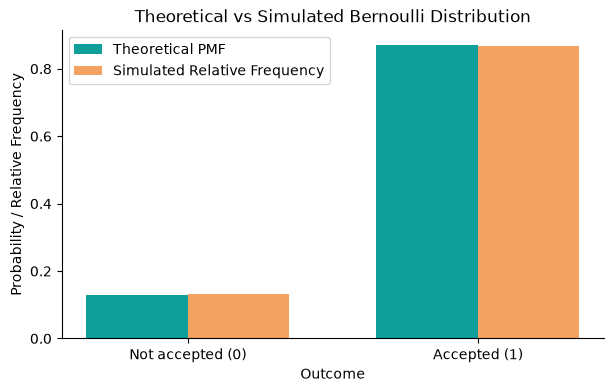

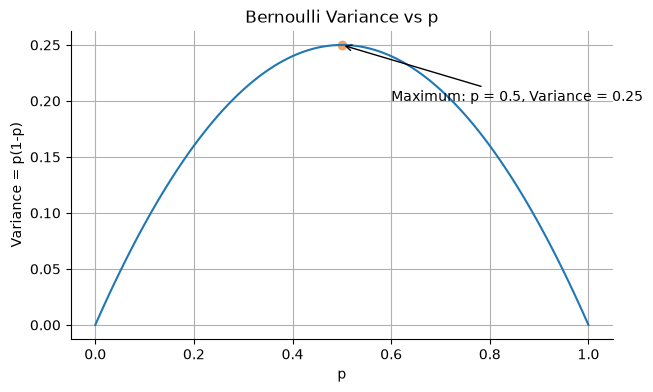

In [4]:
# Part A — Bernoulli Distribution
# Q2 — Estimating p from attendance data

n = 2000
successes = 1740

# Estimate p
p_hat = successes / n

print("Estimated p:", p_hat)

# Simulate 2000 Bernoulli trials
simulated = stats.bernoulli.rvs(
    p_hat,
    size=n,
    random_state=42
)

# Simulated proportion of successes
simulated_proportion = np.mean(simulated)

print("Theoretical p:", p_hat)
print("Simulated proportion:", simulated_proportion)

# Outcomes
x = np.array([0, 1])

# Theoretical PMF
theoretical_pmf = stats.bernoulli.pmf(x, p_hat)

# Simulated relative frequencies
simulated_relative_frequency = np.array([
    np.mean(simulated == 0),
    np.mean(simulated == 1)
])

# Grouped bar chart
width = 0.35

plt.figure()

plt.bar(
    x - width/2,
    theoretical_pmf,
    width,
    color=DISCRETE_COLOR,
    label="Theoretical PMF"
)

plt.bar(
    x + width/2,
    simulated_relative_frequency,
    width,
    color=HIGHLIGHT_COLOR,
    label="Simulated Relative Frequency"
)

plt.xticks(x, ["Not accepted (0)", "Accepted (1)"])
plt.xlabel("Outcome")
plt.ylabel("Probability / Relative Frequency")
plt.title("Theoretical vs Simulated Bernoulli Distribution")
plt.legend()

plt.show()


# Variance for p from 0 to 1
p_values = np.linspace(0, 1, 101)
variances = p_values * (1 - p_values)

# Find maximum variance
max_index = np.argmax(variances)
max_p = p_values[max_index]
max_variance = variances[max_index]

# Second figure
plt.figure()

plt.plot(p_values, variances)

# Mark maximum point
plt.scatter(max_p, max_variance, color=HIGHLIGHT_COLOR)

plt.annotate(
    f"Maximum: p = {max_p:.1f}, Variance = {max_variance:.2f}",
    xy=(max_p, max_variance),
    xytext=(0.6, 0.20),
    arrowprops=dict(arrowstyle="->")
)

plt.xlabel("p")
plt.ylabel("Variance = p(1-p)")
plt.title("Bernoulli Variance vs p")
plt.grid(True)

plt.show()

---
# Part B — Binomial distribution
*Recall:* $P(X=k) = \binom{n}{k}p^k(1-p)^{n-k}$, $\;E[X]=np$, $\;Var(X)=np(1-p)$.

## Q3. Guessing a multiple-choice quiz &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📝 An online quiz has **12 multiple-choice questions**, each with **4 options** and exactly one correct answer. A student who has not studied guesses every answer at random. Let $X$ = number of questions answered correctly.
>
> **(a)** State $n$ and $p$, check that the **BINS** conditions hold, and compute $P(X=5)$ **by hand**, showing the value of $\binom{12}{5}$.
> **(b)** Find the mean and the variance of $X$.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
>

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:
### (a) State n and p, check BINS conditions, and compute P(X = 3)

Given:

Number of questions = 12

Therefore,

n = 12

Each question has 4 options and exactly 1 option is correct.

Therefore, the probability of getting a question correct is:

p = 1/4 = 0.25

The probability of getting a question wrong is:

q = 1 - p

q = 1 - 0.25

q = 0.75

BINS conditions:

B — Binary outcome: Each question is either correct or incorrect.

I — Independent trials: The answer to one question does not affect another question.

N — Number of trials is fixed: There are exactly 12 questions.

S — Same probability: The probability of a correct answer is p = 0.25 for every question.

Therefore, all BINS conditions are satisfied.

Hence,

X ~ Binomial(n = 12, p = 0.25)

Using the binomial PMF:

P(X = k) = C(n,k) p^k (1-p)^(n-k)

For X = 3:

P(X = 3) = C(12,3)(0.25)^3(0.75)^9

Here,

C(12,3) = 12! / (3!9!)

```
      = 220
```

Therefore,

P(X = 3) = 220(0.25)^3(0.75)^9

```
      = 0.2581
```

Therefore,

P(X = 3) ≈ 0.2581

### (b) Find the mean and variance

For a Binomial distribution:

Mean = np

Mean = 12 × 0.25

Mean = 3

Therefore,

Mean = 3

Variance = np(1-p)

Variance = 12 × 0.25 × (1 - 0.25)

Variance = 12 × 0.25 × 0.75

Variance = 2.25

Therefore,

Variance = 2.25


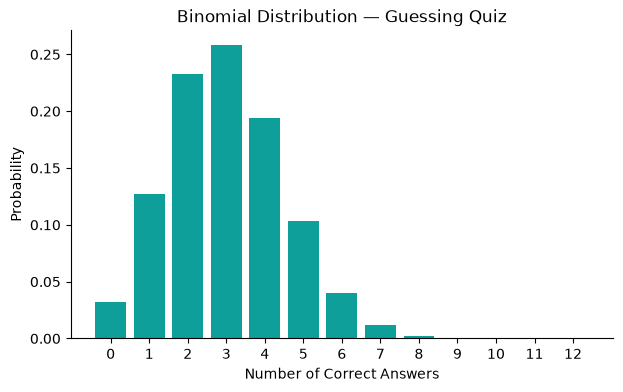

In [5]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
# Part B — Binomial Distribution
# Guessing a multiple-choice quiz

n = 12
p = 0.25

# Values of X from 0 to 12
x = np.arange(0, n + 1)

# Binomial PMF
pmf = stats.binom.pmf(x, n, p)

# Bar chart
plt.bar(x, pmf, color=DISCRETE_COLOR)

plt.xlabel("Number of Correct Answers")
plt.ylabel("Probability")
plt.title("Binomial Distribution — Guessing Quiz")
plt.xticks(x)

plt.show()


# ------------------------------------------------------------

#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> 
> 
> 
> 
> 


---
# Part C — Poisson distribution
*Recall:* $P(X=k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$, $\;E[X]=Var(X)=\lambda$.

## Q5. Help-desk emails &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📧 The IT help-desk of a college receives on average **3 emails per hour**. Let $X$ = number of emails received in one hour.
>
> **(a)** Compute $P(X = 0)$ and $P(X = 2)$ **by hand**, showing the substitution into the formula ($e^{-3} \approx 0.0498$).
> **(b)** State the mean and the variance, and explain in one line what is special about them for a Poisson distribution.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
> - prints $P(X=0)$, $P(X=2)$ and $P(X \le 5)$,
> - prints the smallest value of $k$ for which $P(X \le k) \ge 0.95$ (use `.ppf` or a loop).

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:
a) Given,

λ = 3 emails per hour

The Poisson formula is:

P(X = k) = (λ^k e^(-λ)) / k!


For X = 0:

P(X = 0) = (3^0 e^(-3)) / 0!
         = (1)(0.0498) / 1
         = 0.0498


For X = 2:

P(X = 2) = (3^2 e^(-3)) / 2!
         = (9)(0.0498) / 2
         = 0.2240


(b) Mean:

E[X] = λ
     = 3


Variance:

Var(X) = λ
       = 3


The special property of the Poisson distribution is that
the mean and variance are equal.

(a) Probabilities
P(X = 0) = 0.0498
P(X = 2) = 0.2240

(b) Mean and Variance
Mean = 3.0000
Variance = 3.0000
Mean = Variance, which is a special property of the Poisson distribution.


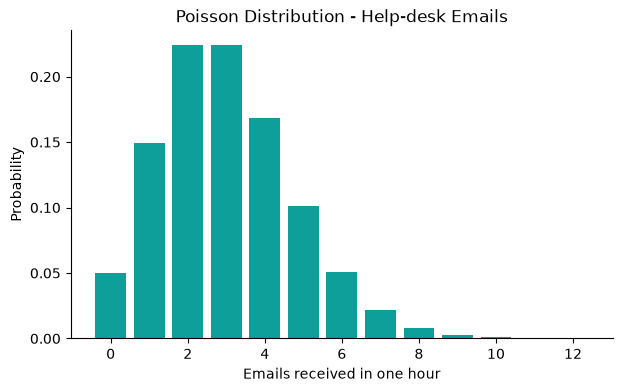


Additional probabilities
P(X = 0) = 0.0498
P(X = 2) = 0.2240
P(X <= 5) = 0.9161
Smallest k for P(X <= k) >= 0.95 = 6
P(X <= k) = 0.9665


In [10]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
# Q5 — Poisson Distribution: Help-desk Emails

# Given
la = 3

# (a) P(X = 0) and P(X = 2)
P_X0 = stats.poisson.pmf(0, la)
P_X2 = stats.poisson.pmf(2, la)

print("(a) Probabilities")
print("P(X = 0) =", f"{P_X0:.4f}")
print("P(X = 2) =", f"{P_X2:.4f}")

# (b) Mean and variance
mean = stats.poisson.mean(la)
variance = stats.poisson.var(la)

print("\n(b) Mean and Variance")
print("Mean =", f"{mean:.4f}")
print("Variance =", f"{variance:.4f}")
print("Mean = Variance, which is a special property of the Poisson distribution.")

# (c) PMF for k = 0 to 12
k = np.arange(0, 13)
pmf = stats.poisson.pmf(k, la)

plt.bar(k, pmf, color=DISCRETE_COLOR)

plt.xlabel("Emails received in one hour")
plt.ylabel("Probability")
plt.title("Poisson Distribution - Help-desk Emails")

plt.show()

# Additional probabilities
P_X_le_5 = stats.poisson.cdf(5, la)

print("\nAdditional probabilities")
print("P(X = 0) =", f"{P_X0:.4f}")
print("P(X = 2) =", f"{P_X2:.4f}")
print("P(X <= 5) =", f"{P_X_le_5:.4f}")

# Smallest k for which P(X <= k) >= 0.95
k_95 = stats.poisson.ppf(0.95, la)

print("Smallest k for P(X <= k) >= 0.95 =", int(k_95))
print(
    "P(X <= k) =",
    f"{stats.poisson.cdf(int(k_95), la):.4f}"
)


# ---------------------------------------------
# ------------------------------------------------------------

## Q6. Server errors over a night shift &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 🖥️ A web server logs errors at an average rate of **1.5 errors per hour**. The night shift runs from 10 pm to 6 am, i.e. **8 hours**.
>
> **(a)** Find the value of $\lambda$ for the **whole 8-hour shift**, and compute by hand the probability of a **clean shift** (zero errors in the 8 hours).
> **(b)** State the mean and variance for the 8-hour window. The on-call engineer is paged if **more than 18 errors** occur in the shift — write the expression for that probability and name the `scipy` function that gives it directly.
> **(c)** Write Python code that:
> - creates **two subplots side by side** — the PMF for the 1-hour window ($\lambda = 1.5$) and the PMF for the 8-hour window — each with its own sensible range of $k$, title and labels,


#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:
### (a) Find λ for the 8-hour shift and probability of a clean shift

Given:

Average error rate = 1.5 errors per hour

Time period = 8 hours

For a Poisson distribution:

λ = Rate × Time

λ = 1.5 × 8

λ = 12

Therefore,

λ = 12 errors for the 8-hour shift.

For a clean shift, there must be zero errors.

Therefore,

P(X = 0) = (e^(-λ) λ^0) / 0!

Substituting λ = 12:

P(X = 0) = (e^(-12) × 12^0) / 0!

P(X = 0) = e^(-12)

P(X = 0) ≈ 0.0000061442

Therefore,

P(X = 0) ≈ 0.00000614

### (b) Mean, variance and probability of more than 18 errors

For a Poisson distribution:

Mean = λ

Variance = λ

For the 8-hour shift:

Mean = 12

Variance = 12

Therefore,

Mean = 12

Variance = 12

The engineer is paged if more than 18 errors occur.

The required probability is:

P(X > 18)

Using the Poisson survival function:

P(X > 18) = sf(18, λ)

Therefore, the scipy function that gives this probability directly is:

stats.poisson.sf(18, 12)


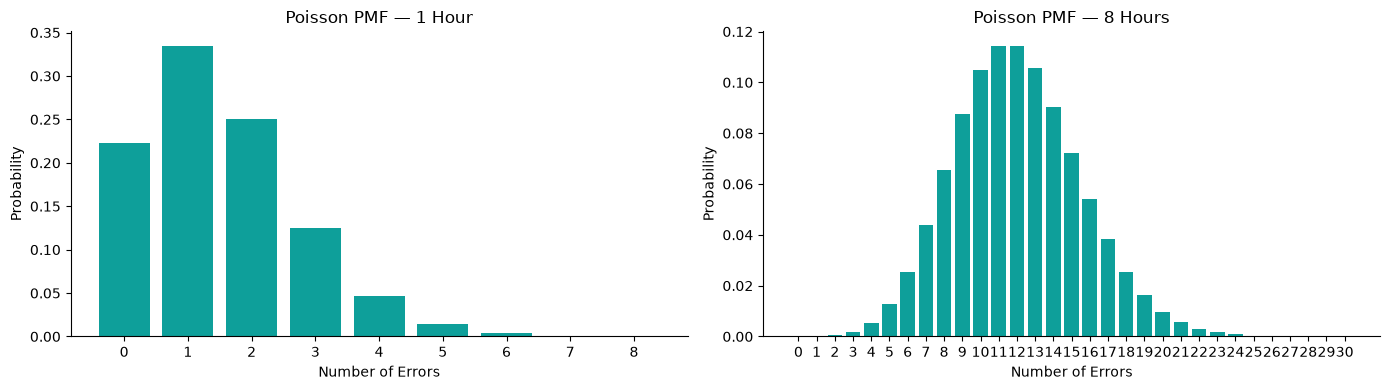

In [6]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
# Part C — Poisson Distribution
# Q6 — Server Errors Over a Night Shift

lambda_1hour = 1.5
lambda_8hour = 1.5 * 8

# 1-hour PMF
x_1hour = np.arange(0, 9)
pmf_1hour = stats.poisson.pmf(x_1hour, lambda_1hour)

# 8-hour PMF
x_8hour = np.arange(0, 31)
pmf_8hour = stats.poisson.pmf(x_8hour, lambda_8hour)

# Two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1-hour window
axes[0].bar(x_1hour, pmf_1hour, color=DISCRETE_COLOR)
axes[0].set_title("Poisson PMF — 1 Hour")
axes[0].set_xlabel("Number of Errors")
axes[0].set_ylabel("Probability")
axes[0].set_xticks(x_1hour)

# 8-hour window
axes[1].bar(x_8hour, pmf_8hour, color=DISCRETE_COLOR)
axes[1].set_title("Poisson PMF — 8 Hours")
axes[1].set_xlabel("Number of Errors")
axes[1].set_ylabel("Probability")
axes[1].set_xticks(x_8hour)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------

---
# Part D — Normal distribution
*Recall:* $f(x)=\dfrac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/2\sigma^2}$, $\;Z=\dfrac{X-\mu}{\sigma}$, $\;E[X]=\mu$, $\;Var(X)=\sigma^2$.

## Q7. Battery life of a phone &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🔋 The battery life of a phone model is normally distributed with a mean of **18 hours** and a standard deviation of **1.5 hours**. Let $X$ = battery life of a randomly chosen phone.
>
> **(a)** Compute the **Z-score** for a battery life of 15 hours and say in words what that Z-score means.
> **(b)** Using the 68–95–99.7 rule, state the interval of battery lives that contains about **95%** of the phones. Show how you obtained it.
> **(c)** Write Python code that:
> - generates 400 equally spaced values of $x$ over $\mu \pm 4\sigma$ and computes the PDF,
> - plots the curve in `CONTINUOUS_COLOR` with a title and axis labels,
.

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:
### Given:

Mean, μ = 18 hours
Standard deviation, σ = 1.5 hours

### (a) Z-score for battery life = 15 hours

Formula:

Z = (X − μ) / σ

Substitute:

Z = (15 − 18) / 1.5

Z = −3 / 1.5

**Z = −2**

**Meaning:** A battery life of 15 hours is **2 standard deviations below the mean**.

### (b) Interval containing about 95% of phones

According to the **68–95–99.7 rule**, about 95% of observations lie within **2 standard deviations** of the mean.

Therefore:

μ − 2σ ≤ X ≤ μ + 2σ

= 18 − 2(1.5) ≤ X ≤ 18 + 2(1.5)

= 18 − 3 ≤ X ≤ 18 + 3

**15 ≤ X ≤ 21 hours**

Therefore, about **95% of the phones have battery lives between 15 hours and 21 hours**.


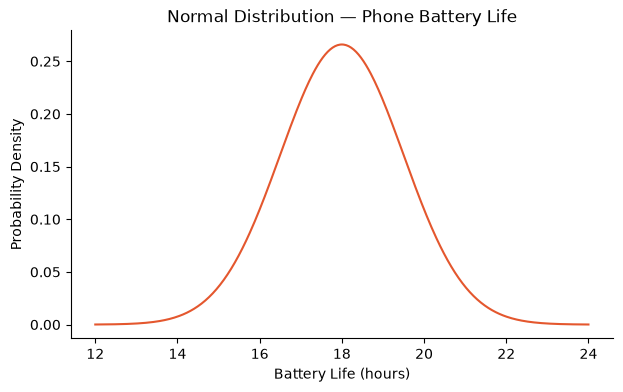

In [7]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
mu = 18
sigma = 1.5

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
pdf = stats.norm.pdf(x, mu, sigma)

plt.plot(x, pdf, color=CONTINUOUS_COLOR)
plt.xlabel("Battery Life (hours)")
plt.ylabel("Probability Density")
plt.title("Normal Distribution — Phone Battery Life")
plt.show()
# ------------------------------------------------------------

## Q8. Calibrating a coffee machine &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> ☕ A vending machine fills cups with coffee. The fill volume is normally distributed with a mean of **200 ml**, but the standard deviation is **not known**. The service log shows that **2.5% of cups overflow**, which happens whenever the fill exceeds **210 ml**.
>
> **(a)** Using the standard normal value $z_{0.975} \approx 1.96$, find the standard deviation $\sigma$ of the fill volume. Show the working.
> **(b)** With that $\sigma$, find the volume below which only **1%** of cups fall (the 1st percentile), and state which `scipy` function gives it. A customer complains if the cup holds less than **190 ml** — write the expression for that probability.
> **(c)** Write Python code that:
> - computes $\sigma$ using `stats.norm.ppf` rather than the rounded 1.96,
> - plots the PDF over a sensible range in `CONTINUOUS_COLOR`,



#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:
### Given:

Mean, μ = 200 ml

P(X > 210) = 0.025

Therefore,

P(X ≤ 210) = 1 − 0.025 = 0.975

For the standard normal distribution:

z₀.₉₇₅ ≈ 1.96

### (a) Find the standard deviation σ

Formula:

Z = (X − μ) / σ

Substitute:

1.96 = (210 − 200) / σ

1.96 = 10 / σ

σ = 10 / 1.96

**σ ≈ 5.10 ml**

Therefore, the standard deviation of the fill volume is approximately:

**σ ≈ 5.10 ml**

### (b) Find the 1st percentile

The 1st percentile means:

P(X ≤ x) = 0.01

Using the standard normal distribution:

z₀.₀₁ ≈ −2.3263

Using:

x = μ + zσ

x = 200 + (−2.3263)(5.10)

x ≈ 200 − 11.87

**x ≈ 188.13 ml**

Therefore, the **1st percentile is approximately 188.13 ml**.

The SciPy function used to find a percentile is:

**`stats.norm.ppf(0.01, loc=200, scale=σ)`**

For a customer complaining when the cup holds less than 190 ml:

**P(X < 190) = stats.norm.cdf(190, loc=200, scale=σ)**

or mathematically:

P(X < 190) = P(Z < (190 − 200)/5.10)

= P(Z < −1.96)


z(0.975): 1.959963984540054
Standard deviation: 5.102134569246539
1st percentile: 188.13066009176305
P(X < 190): 0.025


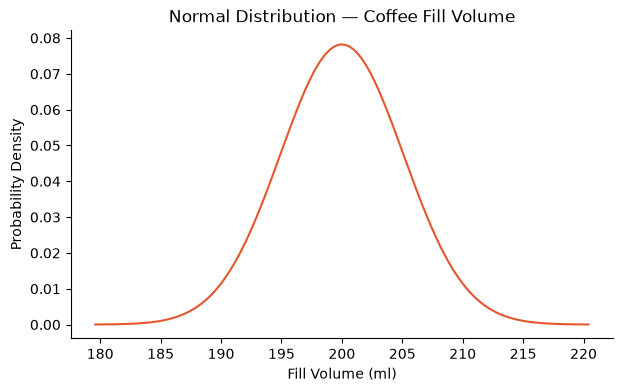

In [8]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------
mu = 200

z_975 = stats.norm.ppf(0.975)
sigma = (210 - mu) / z_975

print("z(0.975):", z_975)
print("Standard deviation:", sigma)

percentile_1 = stats.norm.ppf(0.01, loc=mu, scale=sigma)
print("1st percentile:", percentile_1)

prob_less_190 = stats.norm.cdf(190, loc=mu, scale=sigma)
print("P(X < 190):", prob_less_190)

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
pdf = stats.norm.pdf(x, loc=mu, scale=sigma)

plt.plot(x, pdf, color=CONTINUOUS_COLOR)
plt.xlabel("Fill Volume (ml)")
plt.ylabel("Probability Density")
plt.title("Normal Distribution — Coffee Fill Volume")
plt.show()

# ------------------------------------------------------------

---
# Part E — Uniform distribution
*Recall:* $f(x)=\dfrac{1}{b-a}$ for $a \le x \le b$, $\;P(c \le X \le d)=\dfrac{d-c}{b-a}$, $\;E[X]=\dfrac{a+b}{2}$, $\;Var(X)=\dfrac{(b-a)^2}{12}$.

⚠️ **Note on `scipy`:** for a uniform distribution on $[a, b]$ you must use `loc=a` and `scale=b-a`, **not** `loc=a, scale=b`.

## Q9. Waiting for the campus shuttle &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🚌 The campus shuttle leaves the gate exactly every **15 minutes**. A student walks up to the stop at a completely random moment, so her waiting time $X$ is uniformly distributed between **0 and 15 minutes**.
>

> **(a)** Find the mean waiting time and the variance, showing the substitution.
> **(b)** Write Python code that:
> - plots the PDF as a flat line/rectangle over $[0, 15]$ in `CONTINUOUS_COLOR` (extend the x-axis a little beyond the range so the flat top is clear),


#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> 
> 
> 
> 
> 


In [ ]:
### Given:

Lower limit, a = 0 minutes

Upper limit, b = 15 minutes

Therefore,

**X ~ Uniform(0, 15)**

### (a) Mean waiting time

Formula:

μ = (a + b) / 2

Substitute:

μ = (0 + 15) / 2

**μ = 7.5 minutes**

### Variance

Formula:

σ² = (b − a)² / 12

Substitute:

σ² = (15 − 0)² / 12

= 15² / 12

= 225 / 12

**σ² = 18.75 minutes²**

Therefore:

**Mean = 7.5 minutes**

**Variance = 18.75 minutes²**


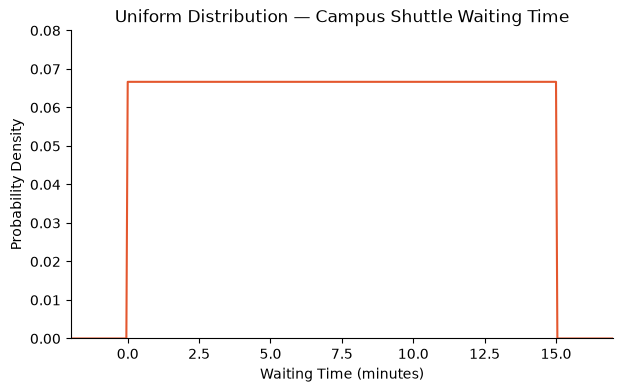

In [9]:
# ✏️ WRITE YOUR CODE HERE
# ------------------------------------------------------------

a = 0
b = 15

x = np.linspace(-2, 17, 400)
pdf = stats.uniform.pdf(x, loc=a, scale=b-a)

plt.plot(x, pdf, color=CONTINUOUS_COLOR)
plt.xlabel("Waiting Time (minutes)")
plt.ylabel("Probability Density")
plt.title("Uniform Distribution — Campus Shuttle Waiting Time")
plt.xlim(-2, 17)
plt.ylim(0, 0.08)
plt.show()


# ------------------------------------------------------------